# Image Basics and NDVI

*Section 1 — Getting started, notebook 1 of 1.* Previous: none. Next: `02_making_maps/01_intro_matplotlib.ipynb`.

**You will learn:**
- how to read basic image information (size, resolution, bands, projection, extent) with rsgispy;
- how to calculate NDVI in three ways: `calc_indices`, `band_maths` and `image_band_math`;
- how to threshold NDVI into a simple classification, saved as a thematic GeoTIFF with class names and colours (`set_thematic_classes`);
- how to make a first map of an image, and show maps side by side with `create_map_panels`.

**Before you start:** nothing — this is the first notebook.

**Data:** `../data/sen2_20210527_aber.tif` (Sentinel-2, Aberystwyth, 27 May 2021).

**Run time:** less than 1 minute.

## Introduction

[rsgispy](https://rsgispy.readthedocs.io) is a set of Python modules for remote sensing and GIS data processing. It is a pure-Python successor to [RSGISLib](http://rsgislib.org), built on [rasterio](https://rasterio.readthedocs.io), [GeoPandas](https://geopandas.org) and NumPy.

The modules provide a set of high level functions, at a similar level to ArcGIS / QGIS toolbox functions or tools in ENVI or Erdas Imagine. The idea is that you can join a number of functions together to undertake your analysis or put those functions within a loop and process a number of input images.

This first tutorial will first show you how to calculate the [Normalised Difference Vegetation Index (NDVI)](https://en.wikipedia.org/wiki/Normalized_difference_vegetation_index) in three ways:

 * Using the `rsgispy.imagecalc.calcindices.calc_indices` function - does everything in one function call, and can calculate many indices at once :)
 * Using the `rsgispy.imagecalc.maths.band_maths` function - which is a very flexible way of doing simple data analysis
 * Using the `rsgispy.imagecalc.maths.image_band_math` function - which is similar to `band_maths` but can only use a single input image

In the second part of the tutorial you will look at using the `rsgispy.imagecalc.maths.band_maths` function to undertake a simple classification using the NDVI image you have calculated. However, the tutorial will start by getting some basic information for our input image and visualising it within the notebook.

NDVI is a useful indice for many vegetation studies and is also useful as it can be calculated from many different multi-spectral dataset:

$$
  \text{NDVI} = \frac{\text{NIR} - \text{RED}}{\text{NIR} + \text{RED}}
$$

**RSGISLib users:** `rsgislib.imagecalc.calcindices.calc_ndvi` (and the other `calc_*` index functions) are replaced by the single `calc_indices` function, and `band_math` is now called `band_maths`. See the [migration guide](https://rsgispy.readthedocs.io/en/latest/guides/migrating_from_rsgislib.html).

## Running Notebook

The notebook has been run and saved with the outputs so you can see what the outputs should be and so the notebook and be browsed online without having to run the notebook for it to make sense. 

If you are running the notebook for yourself it is recommended that you clear the existing outputs which can be done by running one of the following options depending on what system you are using:

**Jupyter-lab**:

> \> _Edit_ \> _'Clear All Outputs'_

**Jupyter-notebook**:

> \> _Cell_ \> _'All Outputs'_ \> _Clear_


## Importing rsgispy Modules

The first step is to import the modules from rsgispy for the analysis we are to undertake:

In [1]:
import os

# The highest level of the rsgispy module, which defines data types
# (e.g., rsgispy.TYPE_32FLOAT) and a number of other constants.
import rsgispy

# The rsgispy image maths module which has the band_maths
# and image_band_math functions.
import rsgispy.imagecalc.maths

# The rsgispy image indices module which provides a function for
# calculating a number of standard remote sensing image indices
# and band ratios.
import rsgispy.imagecalc.calcindices

# The rsgispy image utilities modules for reading image metadata,
# calculating image statistics and defining colour tables.
import rsgispy.imageutils.metadata
import rsgispy.imageutils.stats
import rsgispy.imageutils.colourtable

# All the outputs from this notebook are written to the outputs directory
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

## Importing Other Modules

For visualising the results with a notebook there are other modules we need to import but if undertaking the analysis locally on your computer you can use your prefer data viewer (e.g., [TuiView](http://tuiview.org) or [QGIS](https://www.qgis.org))

In [2]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import matplotlib.pyplot as plt

# Import the rsgispy raster mapping module which has functions for helping
# to read and visualise image data within a plot
import rsgispy.mapping.raster

# The rsgispy map layout module, which can draw several maps side by side
import rsgispy.mapping.layout as map_layout

## 1. Basic Image metadata

First you will query the input image to find the size (i.e., number of pixels in the x and y axis'), the image resolution, number of bands, band names, projection and get the spatial coordinates of the image bounding box.

In [3]:
# Define the input image path
input_img = "../data/sen2_20210527_aber.tif"

### 1.1. Image Size

In [4]:
# Call function to get the input image size:
x_size, y_size = rsgispy.imageutils.metadata.get_img_size(input_img)

# Output the x_size, y_size variables with some formatting
f"{x_size} x {y_size}"

'931 x 947'

### 1.2. Image Resolution

In [5]:
# Call function to get the input image resolution:
x_res, y_res = rsgispy.imageutils.metadata.get_img_res(input_img)


# Output the x_res, y_res variables with some formatting
f"({x_res}, {y_res})"

'(10.0, -10.0)'

### 1.3. Number of Image Bands

In [6]:
n_bands = rsgispy.imageutils.metadata.get_img_band_count(input_img)
f"Number of Bands: {n_bands}"

'Number of Bands: 10'

### 1.4. Image Band Names 

In [7]:
band_names = rsgispy.imageutils.metadata.get_band_names(input_img)

band_names

['Blue',
 'Green',
 'Red',
 'RE_B5',
 'RE_B6',
 'RE_B7',
 'NIR_B8',
 'NIR_B8A',
 'SWIR1',
 'SWIR2']

### 1.5. Image Projection

In [8]:
wkt_str = rsgispy.imageutils.metadata.get_wkt_proj_from_img(input_img)

# The image is projected using the British National Grid.
# The WKT string for this projection will be provided:

wkt_str

'PROJCS["OSGB36 / British National Grid",GEOGCS["OSGB36",DATUM["Ordnance_Survey_of_Great_Britain_1936",SPHEROID["Airy 1830",6377563.396,299.3249646,AUTHORITY["EPSG","7001"]],AUTHORITY["EPSG","6277"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4277"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",49],PARAMETER["central_meridian",-2],PARAMETER["scale_factor",0.9996012717],PARAMETER["false_easting",400000],PARAMETER["false_northing",-100000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","27700"]]'

In [9]:
epsg_code = rsgispy.imageutils.metadata.get_epsg_proj_from_img(input_img)

# The image is projected using the British National Grid.
# The EPSG code for the project should be outputted (27700):

epsg_code

27700

### 1.6. Spatial Boundary Box 

In [10]:
img_bbox = rsgispy.imageutils.metadata.get_img_bbox(input_img)

# The bbox is ordered as (min_x, max_x, min_y, max_y)

f"X: [{img_bbox[0]}, {img_bbox[1]}], Y: [{img_bbox[2]}, {img_bbox[3]}]"

'X: [257060.59483340546, 266370.59483340546], Y: [276258.7167059921, 285728.7167059921]'

## 2. Visualing the Input Image

Visualising our image is something we would normally do within our GIS. Do visual the image we would undertake two key steps:

 * Selecting the image bands for display - in this case NIR, SWIR1 and Red (8, 9, 3)
 * Stretching the data so the value are within the 0 -- 255 range required for visualisation.

Stretching not only rescales the image data, for visualisation to a range of 0--255, but also aims to enhance the information content so we can see as much of the 'useful' information as possible. Typically this involves removing some of the lowest values, with these being set of a value of 0(i.e., black), and some of the highest values with these being set of 255 (i.e., white). This allows the majority of the image pixel values to be represented by the range 0--255 rather than outliers compressing the numerical range for the majority.

For the example below we are using a cumulative stretch (`rsgispy.IMG_STRETCH_CUMULATIVE`), which uses the 2nd and 98th percentiles of each band as the lower and upper limits. An alternative is a standard deviation stretch (`rsgispy.IMG_STRETCH_STDEV`), where the mean $\pm$ 2 standard deviations provides the lower and upper limits (the thresholds cannot go beyond the image minimum and maximum). The different stretches are compared in the next section, *Making maps*.

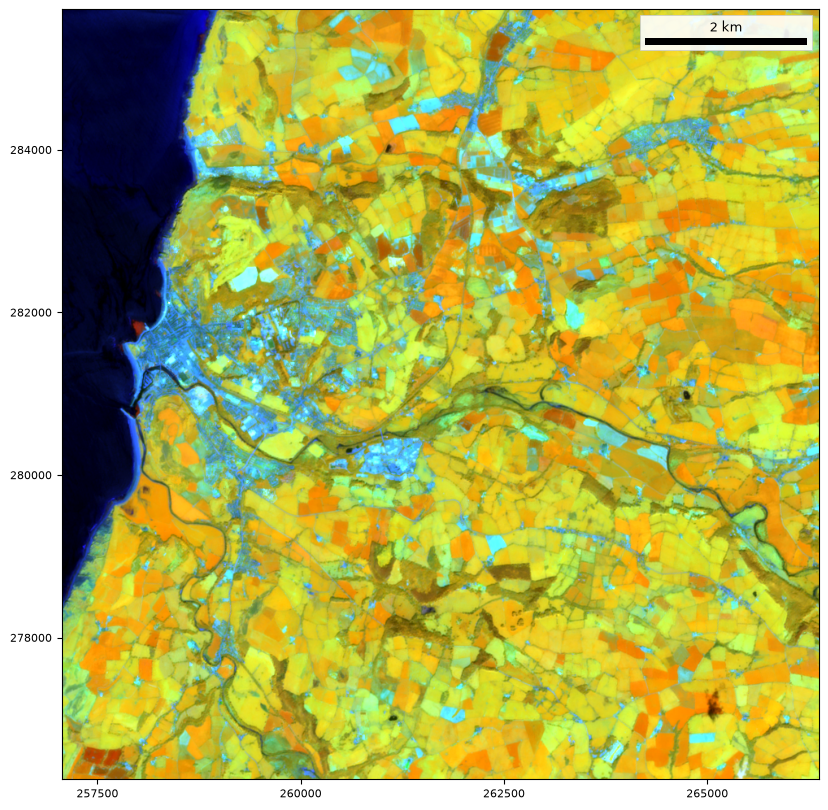

In [11]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(10, 10))

# Plot the image data using bands 8, 9, 3 (NIR, SWIR1, Red)
# which produces a good false colour visualisation which is
# good at picking out vegetation. If you want a true colour
# (i.e., Red, Green, Blue) visualisation change the bands to
# [3, 2, 1]
# The function returns the matplotlib image (an AxesImage) it has drawn.
# Assigning it to a variable stops the notebook printing it.
img_artist = rsgispy.mapping.raster.create_raster_img_map(
    ax, input_img, img_bands=[8, 9, 3], img_stch=rsgispy.IMG_STRETCH_CUMULATIVE
)

## 3. GeoTIFF Output Options

All the images written in these tutorials use the GeoTIFF format (`gdalformat="GTIFF"`), which is widely supported by other applications 'out of the box'. By default GeoTIFF doesn't compress or tile the data, but rsgispy writes tiled, DEFLATE-compressed GeoTIFFs by default, so no extra set-up is needed.

If you want different options for a particular output (e.g., LZW compression), most rsgispy functions which write an image take a `creation_opts` dictionary of GDAL creation options, e.g., `creation_opts={"COMPRESS": "LZW"}`.

**RSGISLib users:** the `set_env_vars_lzw_gtiff_outs` / `set_env_vars_deflate_gtiff_outs` calls are no longer needed (they still exist in `rsgispy.imageutils.envopts` if you want them). The KEA format is not used, as the rasterio pip packages have no KEA driver.

In [12]:
# Print the default GeoTIFF creation options rsgispy uses:
import rsgispy.imageutils.envopts

rsgispy.imageutils.envopts.get_gdal_img_creation_opts("GTIFF")

{'TILED': 'YES',
 'COMPRESS': 'DEFLATE',
 'INTERLEAVE': 'BAND',
 'BIGTIFF': 'IF_SAFER'}

## 4. Calculating NDVI using `calc_indices` Function

The `calc_indices` function can calculate many indices (NDVI, NDWI, EVI, ...) in one pass, writing one output band per index. You tell it which input bands are which (e.g., `{3: "red", 8: "nir"}`) and give a list of the indices to calculate. The full list of indices is given by `rsgispy.imagecalc.calcindices.get_available_indices()`.

You can read the documentation for this function on the website: https://rsgispy.readthedocs.io

In [13]:
# The red band is band 3 - Note band numbering starts at 1.
img_red_band = 3

# The NIR band is band 8
img_nir_band = 8

# The output image file
ndvi_output_img = os.path.join(out_dir, "sen2_20210527_aber_ndvi.tif")

# Specify that image metadata statistics and pyramids
# are to be calculated: calc_stats=True
# Specify that the output format should be
# GeoTIFF: gdalformat='GTIFF'
# The no data value is read from the input image (0) and
# the output no data value is -999.
rsgispy.imagecalc.calcindices.calc_indices(
    input_img,
    ndvi_output_img,
    band_names={img_red_band: "red", img_nir_band: "nir"},
    indices=["NDVI"],
    calc_stats=True,
    gdalformat="GTIFF",
)

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

### Visualise the NDVI result:

To compare the NDVI with the input image we will draw the two maps side by side with `rsgispy.mapping.layout.create_map_panels`. Each panel is described by a dictionary (or a `MapPanel`): its type (`"rgb"` for a stretched 1- or 3-band image, `"cmap"`, `"thematic"` or `"vector"`), the image, the bands and a title. The panels share one extent, and one scale bar and north arrow are drawn on the first panel. The function returns the figure and an array of the axes (`fig, axs`), so you can still change the maps afterwards with matplotlib.

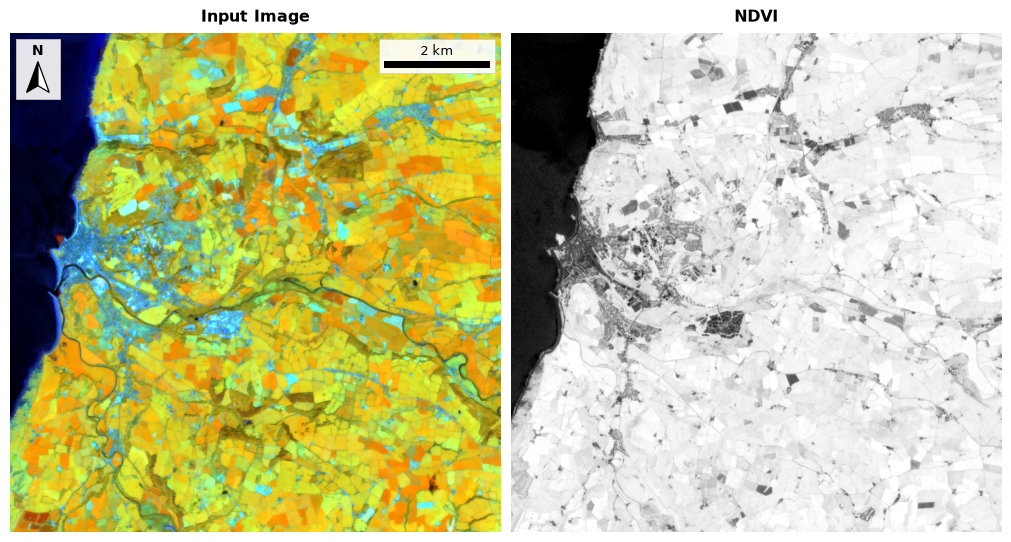

In [14]:
# Draw the input image and the NDVI alongside each other
fig, axs = map_layout.create_map_panels(
    [
        {"panel_type": "rgb", "input_img": input_img, "bands": [8, 9, 3], "title": "Input Image"},
        {"panel_type": "rgb", "input_img": ndvi_output_img, "bands": [1], "title": "NDVI"},
    ]
)

## 5. Calculating NDVI using `band_maths` Function

To illustraing how to use the `rsgispy.imagecalc.maths.band_maths` function NDVI can also be calculated using the following code. However, note this expression does not deal with no data values within the input image as `calc_indices` does.

The `rsgispy.imagecalc.maths.band_maths` function is a flexible function which has lots of uses for data analysis where the pixel value can be calculated from other pixels (e.g., applying an equation). Each `BandDefn` gives a variable name used in the expression, the image file and the band number.

**RSGISLib users:** `band_math` is now `band_maths`, the band definitions come before the keyword-only `gdalformat` and `datatype` arguments, and `pop_img_stats` takes the no data value as its second argument (with `None` meaning no no data value).

In [15]:
# The output image file
ndvi_tmp_output_img = os.path.join(out_dir, "sen2_20210527_aber_ndvi_tmp.tif")

# Define the image bands to variable names to be used within expression
band_defns = list()
band_defns.append(rsgispy.imagecalc.maths.BandDefn("red", input_img, 3))
band_defns.append(rsgispy.imagecalc.maths.BandDefn("nir", input_img, 8))

# Expression
exp = "(nir-red)/(nir+red)"

# Run the band maths function
rsgispy.imagecalc.maths.band_maths(
    ndvi_tmp_output_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
)

# Calculate the meta-data statistics and image pyramids as we have not dealt with no data values
# in the NDVI equation above then we do not have a define no data value to set here:
rsgispy.imageutils.stats.pop_img_stats(
    ndvi_tmp_output_img, no_data_val=None, calc_pyramids=True
)

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

### Visualise the NDVI result:

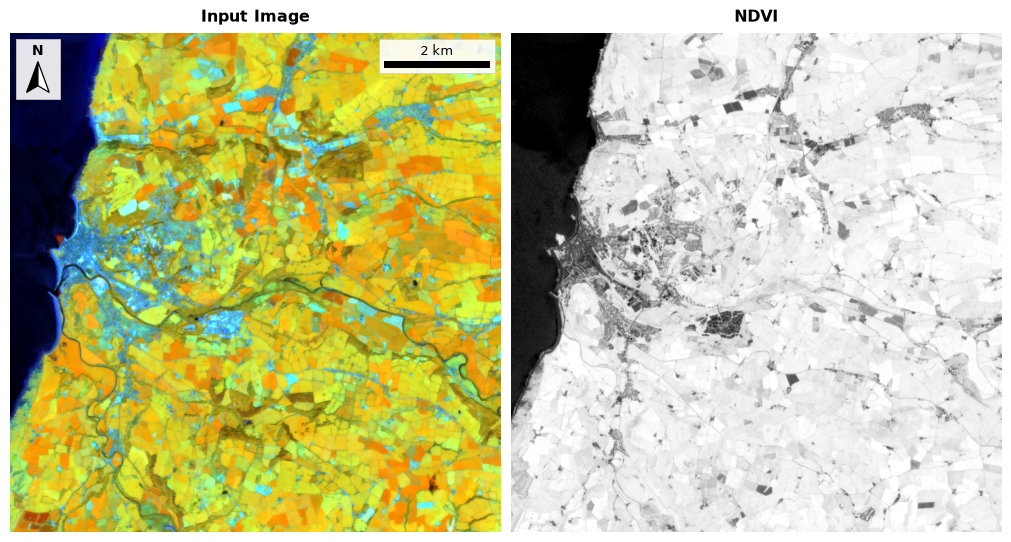

In [16]:
# Draw the input image and the NDVI alongside each other
fig, axs = map_layout.create_map_panels(
    [
        {"panel_type": "rgb", "input_img": input_img, "bands": [8, 9, 3], "title": "Input Image"},
        {"panel_type": "rgb", "input_img": ndvi_tmp_output_img, "bands": [1], "title": "NDVI"},
    ]
)

## 6. Calculating NDVI using `image_band_math` Function:

The `rsgispy.imagecalc.maths.image_band_math` function is similar to the `rsgispy.imagecalc.maths.band_maths` function but only use a single input image where the image bands are referred to as `b1` (band 1), `b2` (band 2), ..., `bn` (band n) within the expression. Please note that band numbering starts at 1.

In [17]:
# The output image file
ndvi_tmp_output_img = os.path.join(out_dir, "sen2_20210527_aber_ndvi_tmp.tif")

# Expression
exp = "(b8-b3)/(b8+b3)"

# Run the band maths function
rsgispy.imagecalc.maths.image_band_math(
    input_img,
    ndvi_tmp_output_img,
    exp,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_32FLOAT,
)

# Calculate the meta-data statistics and image pyramids as we have not dealt with no data values
# in the NDVI equation above then we do not have a define no data value to set here:
rsgispy.imageutils.stats.pop_img_stats(
    ndvi_tmp_output_img, no_data_val=None, calc_pyramids=True
)

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

  0%|          | 0/16 [00:00<?, ?it/s]

### Visualise the NDVI result:

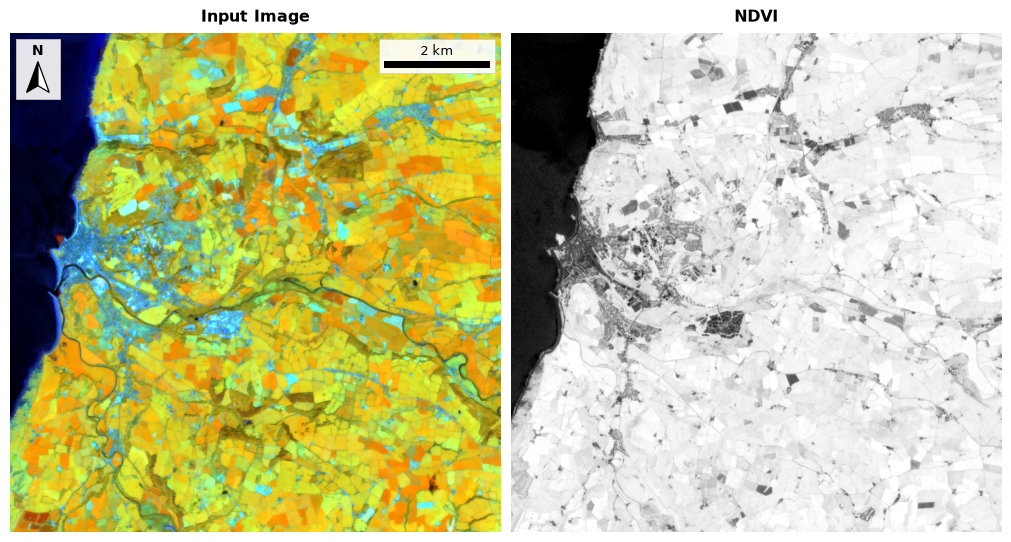

In [18]:
# Draw the input image and the NDVI alongside each other
fig, axs = map_layout.create_map_panels(
    [
        {"panel_type": "rgb", "input_img": input_img, "bands": [8, 9, 3], "title": "Input Image"},
        {"panel_type": "rgb", "input_img": ndvi_tmp_output_img, "bands": [1], "title": "NDVI"},
    ]
)

## 7. Threshold the NDVI into a simple set of classes

The `band_maths` and `image_band_math` function both use the [pymu-eval](https://pypi.org/project/pymu-eval/) library, a Python implementation of the muparser syntax, to parse the expressions passed to the function. [Muparser has the build-in functions](https://beltoforion.de/en/muparser/features.php#idDef1) you could expect of most calculators (e.g., sin, cos, log etc.) but it also has the ability calculate a minimum, maxium and average from a list of input values. However, muparser also has an option to apply an [if-else expression](https://beltoforion.de/en/muparser/features.php#idDef3) and can use [binary operators (e.g., or, and, not.)](https://beltoforion.de/en/muparser/features.php#idDef2) to join expressions together. We will use this functionality to build a basic classification using the NDVI. 

However, first we need to understand the [if-else expression](https://beltoforion.de/en/muparser/features.php#idDef3) syntax of muparser:

> `<expression>?<true value>:<false value>`

> `if <expression> then <true value> else <false value>`

So, if we wanted to use our NDVI to classify vegetated verses non-vegetated pixels then we might use an expression such as:

> `ndvi>0.3?1:2`

In this case pixels with an NDVI greater than 0.3 will be given the pixel value 1 (i.e., the vegetated class) and pixels with a value less or equal to 0.3 will be given a pixel value of 2 (i.e., non-vegetation class). 

We can combine [if-else expressions](https://beltoforion.de/en/muparser/features.php#idDef3) to increase the number of classes to be produced. For example, in the following code we will introduce a highly productive vegetation class for pixels with an NDVI greater than 0.65:

> `ndvi<=0.3?2:ndvi>0.65?3:1`

The expression above contains the following logic: If the NDVI is less than or equal to 0.3 output a pixel value of 2 (i.e., non-vegetated), else if the NDVI is greater than 0.65 then output a pixel value of 3 (i.e., highly productive vegetation) else output a pixel value of 1 (i.e., less productive vegetation). 

You could keep adding else statments to increate the number of classes within your output classification.

The expression above could also be written using the binary operator `and` as follows:

> `(ndvi>0.3)&&(ndvi<=0.65)?1:ndvi<=0.3?2:3`

The expression above contains the following logic but will produce the same result as the expression above: If the NDVI is greater than 0.3 and less than or equal to 0.65 then output a pixel value of 1 (i.e., less productive vegetation), if the NDVI has a value of less than or equal to 0.3 then output a pixel value of 2 (i.e., non-vegetated) otherwise output a value of 3 (i.e., highly productive vegetation) which must have a pixel value greater than 0.65.


The code below uses the thresholds 0.65 and 0.85 (rather than the 0.3 and 0.65 used in the explanation above) as this image is dominated by vegetation, so the higher thresholds give a more interesting result.

**RSGISLib users:** the original tutorial wrote a KEA file with a raster attribute table (RAT) for the classes. rsgispy does not use RATs: `set_thematic_classes` (the equivalent of `rsgislib.rastergis.set_class_names_colours`) marks a GeoTIFF as thematic, writes the class colours into its colour table, stores the class names in the image and calculates the statistics and pyramids, in one call. The mapping functions (e.g., `create_thematic_raster_map` and `create_map_panels`) read the stored names for their legends.

In [19]:
# The output image file. This is a thematic (classification) image,
# so we will give it class names and colours so the classes are
# displayed with sensible colours and named in map legends.
ndvi_cls_output_img = os.path.join(out_dir, "sen2_20210527_aber_ndvi_cls.tif")

# Define the image bands to variable names to be used within expression
# in this case we only have a single band within the image file so using
# the band_maths function isn't really needed but it can be helpful in
# using a named variable in the expression so you know what it refers to.
# In this case, we can shorten the syntax so rather than creating a list
# and then appending the BandDefn objects we can just create the list
# with a single BandDefn object within the list.
band_defns = [rsgispy.imagecalc.maths.BandDefn("ndvi", ndvi_output_img, 1)]

# Expression
exp = "ndvi<=0.65?2:ndvi>0.85?3:1"

# Run the band maths function. Note we have changed the output
# data type to an 8bit unsigned integer (i.e., whole numbers with
# a range of 0 - 255).
rsgispy.imagecalc.maths.band_maths(
    ndvi_cls_output_img,
    exp,
    band_defns,
    gdalformat="GTIFF",
    datatype=rsgispy.TYPE_8UINT,
)

# Give each class (pixel value) a name and a colour. The colours
# are defined with a Red, Green, Blue value between 0 - 255 (a hex
# string such as "#168c22" can also be used). If you search
# "colour picker" in your preferred search engine then you will find
# various online tools for finding the RGB values for a colour.
ndvi_classes = {
    1: ("Vegetation", (22, 140, 34)),
    2: ("Non-vegetation", (163, 163, 163)),
    3: ("Highly productive vegetation", (115, 242, 36)),
}

# set_thematic_classes marks the image as thematic (i.e., the pixel
# values are class labels rather than continuous measurements), writes
# the colour table, stores the class names in the image and, as when
# we calculated the NDVI, populates the image meta-data statistics
# (a histogram of the class values) and builds the pyramids (with
# nearest neighbour resampling). Value 0 is no data.
rsgispy.imageutils.colourtable.set_thematic_classes(ndvi_cls_output_img, ndvi_classes)

  0%|          | 0/16 [00:00<?, ?it/s]

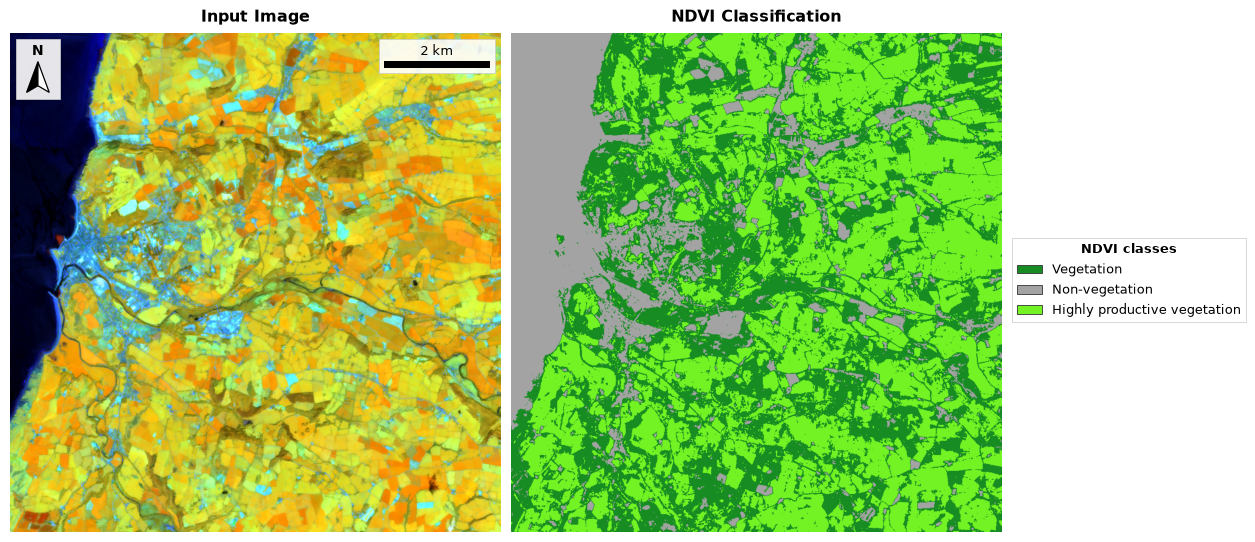

In [20]:
# Draw the input image and the classification alongside each other.
# The legend uses the class names and colours stored in the image.
fig, axs = map_layout.create_map_panels(
    [
        {"panel_type": "rgb", "input_img": input_img, "bands": [8, 9, 3], "title": "Input Image"},
        {"panel_type": "thematic", "input_img": ndvi_cls_output_img, "title": "NDVI Classification"},
    ],
    legend_title="NDVI classes",
)